========== FIRST FIVE ROWS OF THE DATASET ==========

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  

========== DATASET INFORMATION ==========

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        -------------- 

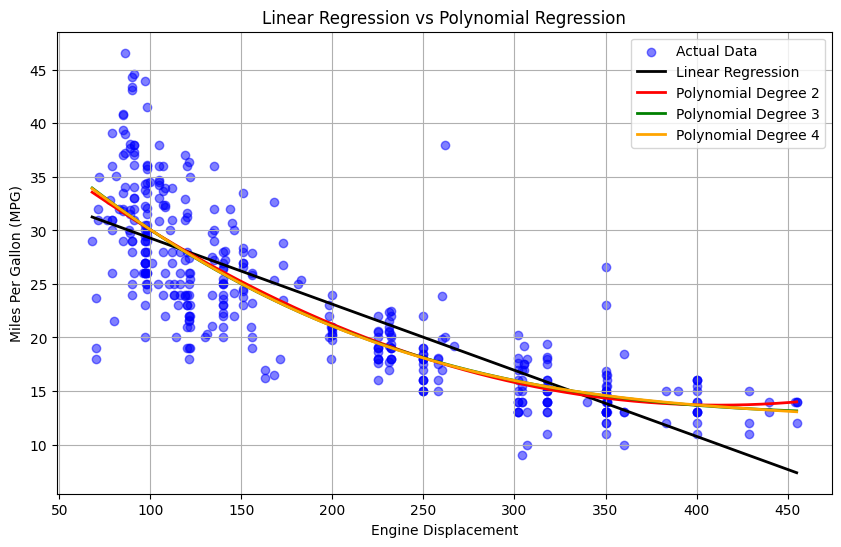

In [4]:
# Polynomial Regression on Auto MPG Dataset

# -------------------------------------------------
# Import Libraries
# -------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# -------------------------------------------------
# Load Dataset
# -------------------------------------------------
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(url)

# -------------------------------------------------
# Display First Five Rows
# -------------------------------------------------
print("========== FIRST FIVE ROWS OF THE DATASET ==========\n")
print(df.head())

# -------------------------------------------------
# Dataset Information
# -------------------------------------------------
print("\n========== DATASET INFORMATION ==========\n")
df.info()

# -------------------------------------------------
# Check Missing Values
# -------------------------------------------------
print("\n========== MISSING VALUES ==========\n")
print(df.isnull().sum())

# -------------------------------------------------
# Select Required Columns and Remove Missing Values
# -------------------------------------------------
df = df[['displacement', 'mpg']].dropna()

print("\nDataset Shape After Removing Missing Values :", df.shape)

# -------------------------------------------------
# Independent and Dependent Variables
# -------------------------------------------------
X = df[['displacement']]
y = df['mpg']

# -------------------------------------------------
# Split Dataset into Training and Testing Sets
# -------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Set Shape :", X_train.shape)
print("Testing Set Shape  :", X_test.shape)

# =====================================================
# LINEAR REGRESSION
# =====================================================
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

print("\n========== LINEAR REGRESSION ==========")
print("Mean Squared Error :", linear_mse)
print("R2 Score           :", linear_r2)

# =====================================================
# POLYNOMIAL REGRESSION (DEGREE 2)
# =====================================================
poly2 = PolynomialFeatures(degree=2)

X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)

poly2_model = LinearRegression()
poly2_model.fit(X_train_poly2, y_train)

y_pred_poly2 = poly2_model.predict(X_test_poly2)

poly2_mse = mean_squared_error(y_test, y_pred_poly2)
poly2_r2 = r2_score(y_test, y_pred_poly2)

print("\n========== POLYNOMIAL REGRESSION (DEGREE 2) ==========")
print("Mean Squared Error :", poly2_mse)
print("R2 Score           :", poly2_r2)

# =====================================================
# POLYNOMIAL REGRESSION (DEGREE 3)
# =====================================================
poly3 = PolynomialFeatures(degree=3)

X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)

poly3_model = LinearRegression()
poly3_model.fit(X_train_poly3, y_train)

y_pred_poly3 = poly3_model.predict(X_test_poly3)

poly3_mse = mean_squared_error(y_test, y_pred_poly3)
poly3_r2 = r2_score(y_test, y_pred_poly3)

print("\n========== POLYNOMIAL REGRESSION (DEGREE 3) ==========")
print("Mean Squared Error :", poly3_mse)
print("R2 Score           :", poly3_r2)

# =====================================================
# POLYNOMIAL REGRESSION (DEGREE 4)
# =====================================================
poly4 = PolynomialFeatures(degree=4)

X_train_poly4 = poly4.fit_transform(X_train)
X_test_poly4 = poly4.transform(X_test)

poly4_model = LinearRegression()
poly4_model.fit(X_train_poly4, y_train)

y_pred_poly4 = poly4_model.predict(X_test_poly4)

poly4_mse = mean_squared_error(y_test, y_pred_poly4)
poly4_r2 = r2_score(y_test, y_pred_poly4)

print("\n========== POLYNOMIAL REGRESSION (DEGREE 4) ==========")
print("Mean Squared Error :", poly4_mse)
print("R2 Score           :", poly4_r2)

# =====================================================
# MODEL COMPARISON
# =====================================================
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression (Degree 2)",
        "Polynomial Regression (Degree 3)",
        "Polynomial Regression (Degree 4)"
    ],
    "MSE": [
        linear_mse,
        poly2_mse,
        poly3_mse,
        poly4_mse
    ],
    "R2 Score": [
        linear_r2,
        poly2_r2,
        poly3_r2,
        poly4_r2
    ]
})

print("\n========== MODEL COMPARISON ==========\n")
print(comparison)


# VISUALIZATION
# =====================================================

# Create smooth values for plotting
X_plot = pd.DataFrame({
    "displacement": np.linspace(
        X["displacement"].min(),
        X["displacement"].max(),
        300
    )
})

plt.figure(figsize=(10, 6))

# Plot Actual Data
plt.scatter(
    X["displacement"],
    y,
    color="blue",
    alpha=0.5,
    label="Actual Data"
)

# -----------------------------
# Linear Regression Line
# -----------------------------
y_linear = linear_model.predict(X_plot)

plt.plot(
    X_plot["displacement"],
    y_linear,
    color="black",
    linewidth=2,
    label="Linear Regression"
)

# -----------------------------
# Polynomial Degree 2
# -----------------------------
X_plot_poly2 = poly2.transform(X_plot)
y_poly2 = poly2_model.predict(X_plot_poly2)

plt.plot(
    X_plot["displacement"],
    y_poly2,
    color="red",
    linewidth=2,
    label="Polynomial Degree 2"
)

# -----------------------------
# Polynomial Degree 3
# -----------------------------
X_plot_poly3 = poly3.transform(X_plot)
y_poly3 = poly3_model.predict(X_plot_poly3)

plt.plot(
    X_plot["displacement"],
    y_poly3,
    color="green",
    linewidth=2,
    label="Polynomial Degree 3"
)

# -----------------------------
# Polynomial Degree 4
# -----------------------------
X_plot_poly4 = poly4.transform(X_plot)
y_poly4 = poly4_model.predict(X_plot_poly4)

plt.plot(
    X_plot["displacement"],
    y_poly4,
    color="orange",
    linewidth=2,
    label="Polynomial Degree 4"
)

# -----------------------------
# Labels
# -----------------------------
plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Linear Regression vs Polynomial Regression")
plt.legend()
plt.grid(True)

plt.show()